# S02 — Préparation à l'échelle : *silver* puis *gold*

```
bronze/yellow_trips ──nettoyage──► silver/yellow_trips ──agrégats + météo──► gold/...  ──► PostgreSQL
```

- **silver** = données propres, typées, une ligne par course
- **gold** = tables prêtes pour les dashboards (une question métier = une table)

In [1]:
import sys; sys.path.append("/home/jovyan/work")
from pyspark.sql import functions as F
from commun.spark_utils import creer_session, RAW, LAKE

from commun.spark_utils import format_tables, vers_postgres
spark = creer_session("S02")
FMT = format_tables(spark)
bronze = spark.read.format(FMT).load(f"{LAKE}/bronze/yellow_trips")
print(f"bronze : {bronze.count():,} lignes")

Préparation de Spark 4.2.0 (Hadoop 3.5.0) + Delta Lake + data lake S3 … le premier démarrage peut prendre quelques minutes.
Session prête. Spark UI : http://localhost:4040
bronze : 3,475,226 lignes


## 1. Règles de nettoyage

Chaque règle est nommée et comptée : on doit pouvoir **justifier** chaque ligne retirée.

In [2]:
MOIS = "2025-01"
import datetime as dt
a, m = map(int, MOIS.split("-"))
debut, fin = f"{MOIS}-01", dt.date(a + (m == 12), m % 12 + 1, 1).isoformat()

regles = {
    "montant_negatif_ou_nul": F.col("total_amount") <= 0,
    "passagers_0_ou_vide":    (F.col("passenger_count") == 0) | F.col("passenger_count").isNull(),
    "distance_aberrante":     (F.col("trip_distance") <= 0) | (F.col("trip_distance") > 100),
    "hors_du_mois":           (F.col("tpep_pickup_datetime") < F.lit(debut)) | (F.col("tpep_pickup_datetime") >= F.lit(fin)),
    "duree_aberrante":        (F.col("tpep_dropoff_datetime") <= F.col("tpep_pickup_datetime")),
}
bronze.select([F.sum(cond.cast("int")).alias(nom) for nom, cond in regles.items()]).show(vertical=True)

-RECORD 0------------------------
 montant_negatif_ou_nul | 63596  
 passagers_0_ou_vide    | 564805 
 distance_aberrante     | 91055  
 hors_du_mois           | 22     
 duree_aberrante        | 2051   



In [3]:
from functools import reduce
a_exclure = reduce(lambda x, y: x | y, regles.values())

silver = (bronze
          .filter(~a_exclure)
          .withColumn("duree_min", (F.unix_timestamp("tpep_dropoff_datetime") - F.unix_timestamp("tpep_pickup_datetime")) / 60)
          .withColumn("heure_pickup", F.date_trunc("hour", "tpep_pickup_datetime"))
          .drop("_source", "_ingere_le"))

silver.write.format(FMT).mode("overwrite").save(f"{LAKE}/silver/yellow_trips")
n_s = spark.read.format(FMT).load(f"{LAKE}/silver/yellow_trips").count()
print(f"silver : {n_s:,} lignes ({n_s / bronze.count():.1%} du bronze conservé)")

silver : 2,815,845 lignes (81.0% du bronze conservé)


## 2. Tables *gold*

Une table par usage. On joint les zones (noms lisibles) et la météo (par heure).

In [ ]:
silver = spark.read.format(FMT).load(f"{LAKE}/silver/yellow_trips")
zones  = spark.read.format(FMT).load(f"{LAKE}/bronze/zones")
meteo  = spark.read.format(FMT).load(f"{LAKE}/bronze/meteo")

z = zones.select(F.col("LocationID").alias("PULocationID"),
                 F.col("Borough").alias("arrondissement"), F.col("Zone").alias("zone"))
# gold 1 : activité par heure et par arrondissement, avec la météo
gold_horaire = (silver.join(z, "PULocationID", "left")
    .groupBy("heure_pickup", "arrondissement")
    .agg(F.count("*").alias("courses"),
         F.round(F.sum("total_amount"), 2).alias("revenu"),
         F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
         F.round(F.avg("tip_amount"), 2).alias("pourboire_moyen"),
         F.round(F.avg("trip_distance"), 2).alias("distance_moyenne"))
    .join(meteo.withColumnRenamed("horodatage", "heure_pickup"), "heure_pickup", "left"))

# gold 2 : synthèse par zone de départ (pour les cartes)
gold_zones = (silver.join(z, "PULocationID", "left")
    .groupBy("PULocationID", "arrondissement", "zone")
    .agg(F.count("*").alias("courses"),
         F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
         F.round(F.avg(F.col("tip_amount") / F.col("total_amount")), 3).alias("taux_pourboire")))

for nom, df in {"trajets_horaires": gold_horaire, "zones": gold_zones}.items():
    df.write.format(FMT).mode("overwrite").save(f"{LAKE}/gold/{nom}")
    print(f"gold/{nom} : {df.count():,} lignes")

gold/trajets_horaires : 4,042 lignes
gold/zones : 251 lignes


## 3. Exposer le *gold* dans PostgreSQL

Superset, Grafana et Streamlit liront ces tables.

In [5]:
vers_postgres(spark.read.format(FMT).load(f"{LAKE}/gold/trajets_horaires"), "gold_trajets_horaires")
vers_postgres(spark.read.format(FMT).load(f"{LAKE}/gold/zones"), "gold_zones")

Table PostgreSQL « gold_trajets_horaires » écrite.
Table PostgreSQL « gold_zones » écrite.


### Relire les tables depuis PostgreSQL

Les tables *gold* sont maintenant dans la base de restitution. On les relit avec pandas, comme le feront les outils de visualisation.

Pour les parcourir à la souris : http://localhost:8080 (Adminer — système *PostgreSQL*, serveur `postgres`, `cours` / `cours`, base `nyctaxi`).

,table_name
0,gold_trajets_horaires
1,gold_zones


gold_trajets_horaires : 4,042 lignes · gold_zones : 251 lignes


,heure_pickup,arrondissement,courses,revenu,prix_moyen,pourboire_moyen,distance_moyenne,temperature_c,precipitation_mm
0,2025-01-01 15:00:00+00:00,Brooklyn,10,289.12,28.91,1.33,4.24,8.1,0.0
1,2025-01-02 01:00:00+00:00,N/A,2,233.00,116.50,0.50,0.08,4.6,0.0
2,2025-01-04 03:00:00+00:00,Manhattan,4336,97006.22,22.37,2.95,2.24,-1.3,0.0
3,2025-01-07 14:00:00+00:00,Unknown,9,258.06,28.67,3.94,3.22,-6.0,0.0
4,2025-01-11 13:00:00+00:00,Bronx,10,372.72,37.27,0.00,9.19,-2.9,0.1


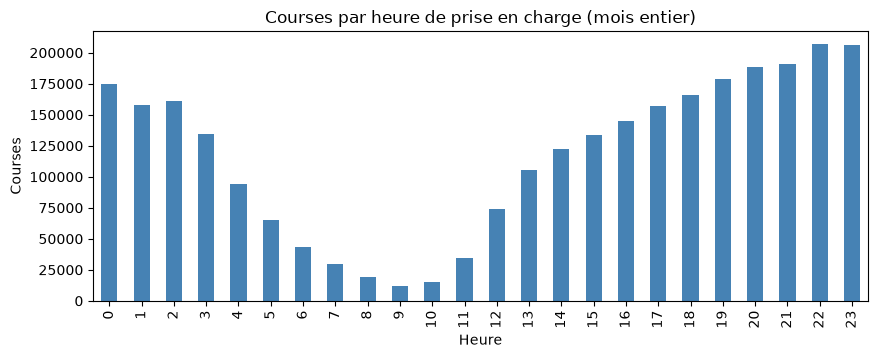

In [6]:
from commun.donnees import lire
import matplotlib.pyplot as plt

# 1. Les tables présentes dans la base
display(lire("SELECT table_name FROM information_schema.tables WHERE table_schema = 'public'"))

# 2. Un aperçu de chaque table gold
horaires = lire("gold_trajets_horaires")
zones = lire("gold_zones")
print(f"gold_trajets_horaires : {len(horaires):,} lignes · gold_zones : {len(zones):,} lignes")
display(horaires.head())

# 3. Un premier graphique, directement depuis PostgreSQL
par_heure = lire("""
    SELECT EXTRACT(HOUR FROM heure_pickup)::int AS heure, SUM(courses) AS courses
    FROM gold_trajets_horaires
    GROUP BY 1 ORDER BY 1
""")
ax = par_heure.plot.bar(x="heure", y="courses", legend=False, color="steelblue", figsize=(10, 3.5))
ax.set(title="Courses par heure de prise en charge (mois entier)", xlabel="Heure", ylabel="Courses")
plt.show()

## 4. Premiers graphiques exploratoires (sur le *gold*, donc petits)

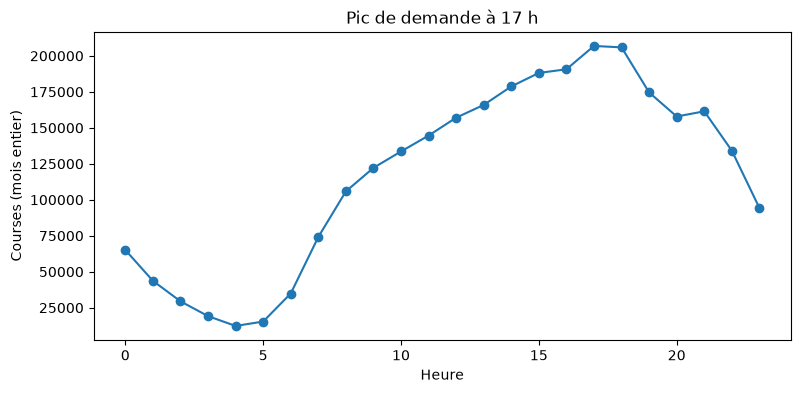

In [7]:
import matplotlib.pyplot as plt
h = (spark.read.format(FMT).load(f"{LAKE}/gold/trajets_horaires")
          .groupBy(F.hour("heure_pickup").alias("heure"))
          .agg(F.sum("courses").alias("courses"))
          .orderBy("heure").toPandas())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(h["heure"], h["courses"], marker="o")
ax.set_xlabel("Heure"); ax.set_ylabel("Courses (mois entier)")
ax.set_title(f"Pic de demande à {int(h.loc[h['courses'].idxmax(), 'heure'])} h")
plt.show()

In [8]:
p = (spark.read.format(FMT).load(f"{LAKE}/gold/trajets_horaires")
          .withColumn("pluie", F.when(F.col("precipitation_mm") > 0, "pluie").otherwise("sec"))
          .groupBy("pluie").agg(F.avg("courses").alias("courses_par_heure_et_arrondissement"))
          .toPandas())
p

,pluie,courses_par_heure_et_arrondissement
0,pluie,787.431487
1,sec,688.228170


## C'est réussi quand…
- `silver` et `gold` sont visibles dans la console RustFS ;
- `SELECT * FROM gold_trajets_horaires LIMIT 10;` répond dans PostgreSQL ;
- vous savez justifier chaque règle de nettoyage et le nombre de lignes retirées.

**Exercice :** ajoutez une table *gold* « aéroports » (zones JFK, LaGuardia, Newark) : courses, prix moyen, durée moyenne par heure.

In [ ]:

# gold 3 : activité par aéroports 
gold_aéroports = (silver.join(z, "PULocationID", "left")
    .groupBy("Zone", "heures_pickup")
    .agg(F.count("*").alias("courses"),
         F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
         F.round(F.avg("trip_duration"), 2).alias("duree_moyenne")))

for nom, df in {"aéroports": gold_aéroports}.items():
    df.write.format(FMT).mode("overwrite").save(f"{LAKE}/gold/{nom}")
    print(f"gold/{nom} : {df.count():,} lignes")

SyntaxError: '(' was never closed (1857107859.py, line 4)

In [ ]:
#CORRECTION

AEROPORTS = [1, 132, 138]

#exercice 

zones  = spark.read.format(FMT).load(f"{LAKE}/bronze/zones")
zones_aero = zones.filter(F.col("LocationID").isin(AEROPORTS)) \
                  .select(F.col("LocationID").alias("PULocationID"),
                          F.col("Zone").alias("aeroport"))

gold_aeroports = (
    silver
    .join(zones_aero, "PULocationID")
    .withColumn("heure", F.date_trunc("hour", "tpep_pickup_datetime"))
    .groupBy("heure", "aeroport")
    .agg(
        F.count("*").alias("nb_courses"),
        F.round(F.avg("total_amount"), 2).alias("prix_moyen"),
        F.round(F.avg("duree_min"), 1).alias("duree_moyenne_min"),
    )
)

gold_aeroports.show(10)

Py4JJavaError: An error occurred while calling o350.load.
: org.apache.spark.SparkException: [INTERNAL_ERROR] No active or default Spark session found SQLSTATE: XX000
	at org.apache.spark.SparkException$.internalError(SparkException.scala:104)
	at org.apache.spark.SparkException$.internalError(SparkException.scala:108)
	at org.apache.spark.sql.SparkSessionCompanion.$anonfun$active$2(SparkSession.scala:1037)
	at scala.Option.getOrElse(Option.scala:201)
	at org.apache.spark.sql.SparkSessionCompanion.$anonfun$active$1(SparkSession.scala:1037)
	at scala.Option.getOrElse(Option.scala:201)
	at org.apache.spark.sql.SparkSessionCompanion.active(SparkSession.scala:1036)
	at org.apache.spark.sql.delta.sources.DeltaDataSource.getTable(DeltaDataSource.scala:112)
	at org.apache.spark.sql.execution.datasources.v2.DataSourceV2Utils$.getTableFromProvider(DataSourceV2Utils.scala:98)
	at org.apache.spark.sql.execution.datasources.v2.DataSourceV2Utils$.loadV2Source(DataSourceV2Utils.scala:148)
	at org.ap

In [9]:
spark.stop()